# Analisis Persona Religion pada ETHICS — Gabungan dan Empat Subset

Notebook ini menyajikan chart gabungan empat subset sebagai bagian utama, lalu
rincian Commonsense, Deontology, Justice, dan Virtue. Cakupan sumber adalah
154.428 respons dari enam model dan 17 persona. I1, I2, dan I3 tetap tersedia
terpisah pada tabel inferensi sesuai Bab VI.

Untuk akurasi Religion, definisi Bab VI dipertahankan: akurasi penuh memakai
seluruh respons sebagai penyebut sehingga abstain dan missing dihitung sebagai
tidak sesuai ground truth. Akurasi committed ditampilkan sebagai metrik
pendamping bersama commit_rate. Chart gabungan memakai distribusi jawaban dan
status, bukan satu skor akurasi moral lintas subset.

## Konsistensi tampilan

Palet persona mengikuti referensi GSM8K Regional: biru, teal, merah, oranye,
hijau tua, hijau muda, ungu, magenta; Neutral abu-abu. Gender menggunakan empat
warna pertama dan abu-abu karena hanya memiliki dua identitas.
Grafik akurasi memakai 3 desimal, anotasi 20 pt,
dan sumbu Y 0–1. Angka lengkap tetap berada di tabel.

Heatmap Regional memakai empat panel dengan 14/14/12/12 perbandingan, masing-masing
menjaga seluruh skenario satu persona atau pasangan tetap bersama. File `07` dan
`09` dengan akhiran `part1` kini berisi **seluruh p-value Exact McNemar**;
`part2` berisi **seluruh p-value Holm**. File `06` dan `08` tetap ukuran efek.
Nama file dipertahankan supaya tautan lama tidak terputus.

Heatmap utama Gender memakai tiga panel: Man (7 perbandingan), Woman (7),
dan Man–Woman (4). P-value mentah dan Holm disajikan terpisah; file `09` lama
menampilkan p-value mentah dan `09_ethics_gender_combined_holm_pvalue_heatmap`
menampilkan Holm. Angka efek menggunakan palet biru–netral–merah yang sama.

Konvensi tanda signifikan tidak diubah: pada Regional, bintang p-value mentah
berarti p mentah < 0,05; pada efek dan Holm berarti p Holm < 0,05. Religion tetap
memakai keputusan Holm pada ketiga heatmap. Warna efek biru–netral–merah berpusat
di nol, dengan rentang simetris yang disesuaikan terhadap data masing-masing grafik.
Jangan membandingkan besar efek hanya dari intensitas warna antargrafik.

Cakupan tidak berubah: akurasi Regional dan Gender memakai Commonsense + Justice;
Religion memakai kecocokan label empat subset pada committed, dengan coverage.
Delta Regional adalah delta akurasi; delta Religion dan Gender adalah delta stance wrong.


## 1. SPEC

Tujuan: menampilkan tiga chart gabungan empat subset, status dan coverage, serta
rincian per subset dalam notebook yang sama. Semua hasil dibaca dari bundle
Religion v3/v4 yang tervalidasi; tidak ada API call, parsing ulang, atau rescoring.

Keterbatasan konstruk Deontology dan Virtue tetap dicatat. Chart per subset
menampilkan akurasi penuh dan committed sesuai naskah, sedangkan distribusi
stance disediakan sebagai informasi tambahan agar perbandingan persona tetap
dapat diperiksa.

## 2. DESIGN PLAN

- Bagian utama: distribusi jawaban gabungan, delta terhadap Neutral, dan delta I–E.
- Bagian berikutnya: tabel serta figure per subset dengan I1, I2, I3 terpisah.
- Status dan coverage selalu ditampilkan bersama akurasi.
- Inferensi antarpersona, antarskenario, Exact McNemar, Q Cochran, Cohen's h,
  dan Holm dibaca dari tabel sumber.
- Semua label figure selain judul dinaikkan 2 pt; judul tetap.

## 3. IMPLEMENTATION — Sumber, tabel, dan bundle revisi

In [1]:
import json, hashlib
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
while not (ROOT / 'result/benchmarks/ethics/runs').is_dir(): ROOT = ROOT.parent
NOTEBOOK_DIR = ROOT / 'notebooks/religion/ethics accuracy analysis'
TABLE_DIR = NOTEBOOK_DIR / 'tables'
FIGURE_DIR = NOTEBOOK_DIR / 'figures'
SOURCE = ROOT / 'result/benchmarks/ethics/reports/Religion_Persona/_combined/persona_publication_analysis_v3_accuracy_paired_holm_six_models'
manifest = json.loads((NOTEBOOK_DIR / 'bundle_manifest.json').read_text(encoding='utf-8'))
summary = pd.read_csv(TABLE_DIR / 'ethics_condition_summary_source_derived.csv')
status = pd.read_csv(TABLE_DIR / 'ethics_status_by_model_persona_category.csv')
accuracy = pd.read_csv(TABLE_DIR / 'ethics_accuracy_by_model_persona_category.csv')
paired_all = pd.read_csv(TABLE_DIR / 'ethics_paired_effects_all.csv')
combined_inference = pd.read_csv(TABLE_DIR / 'ethics_religion_combined_paired_effects_all.csv')
reasons = pd.read_csv(TABLE_DIR / 'ethics_abstain_reasons_by_model.csv')
combined = pd.read_csv(TABLE_DIR / 'ethics_religion_combined_four_subsets.csv')
combined_deltas = pd.read_csv(TABLE_DIR / 'ethics_religion_combined_four_subsets_deltas.csv')
SUBSETS = ['commonsense', 'deontology', 'justice', 'virtue']
print('Rows:', int(summary.total.sum()), '| Models:', summary.model.nunique(), '| Personas:', summary.persona.nunique())
display(summary.groupby('subset').total.agg(['count','sum']))

Rows: 154428 | Models: 6 | Personas: 17


,count,sum
subset,,
commonsense,102,39576
deontology,102,36618
justice,102,27540
virtue,102,50694


## 4. CHECKLIST — Cakupan dan denominator

In [2]:
assert int(summary.total.sum()) == 154428
assert set(summary.subset) == set(SUBSETS)
assert len(summary) == 408
assert len(combined) == 54 and combined.subset_count.eq(4).all()
assert combined.total.eq(combined.committed + combined.abstain + combined.missing).all()
assert combined.n_wrong.add(combined.n_acceptable).eq(combined.committed).all()
assert manifest['api_calls'] == 0 and manifest['rescore'] is False
if 'multiple_comparison_method' in paired_all.columns:
    assert set(paired_all['multiple_comparison_method'].dropna()) <= {'Holm'}
print('[x] 154.428 respons; empat subset; 54 baris gabungan model × kategori persona.')

[x] 154.428 respons; empat subset; 54 baris gabungan model × kategori persona.


## 5. Chart gabungan ETHICS Religion

### Akurasi antar-persona

Grafik ini menyajikan **kecocokan label pada respons committed** dari empat subset,
bukan satu ukuran kemampuan moral. Penggabungan ini ditambahkan atas persetujuan
pengguna; keterbatasan konstruk Deontology/Virtue dan hasil per subset tetap berlaku.
Nilai batang = jumlah `n_correct` / jumlah `committed` lintas subset.
Implicit Avg menggabungkan I1–I3 dengan pembobot jumlah committed, bukan rata-rata
sederhana tiga persentase. Neutral Avg adalah rata-rata enam batang Neutral.
Sumbu Y memakai skala 0–1. Coverage dilaporkan bersama angka grafik di bawah;
perbedaan coverage berarti respons yang dinilai merupakan sampel terseleksi.
Grafik ini berbeda dari heatmap inferensi yang memakai denominator pasangan penuh.

Reproduksi: `python src/MAIN_PARSING/ETHICS/add_religion_ethics_accuracy_chart.py`.


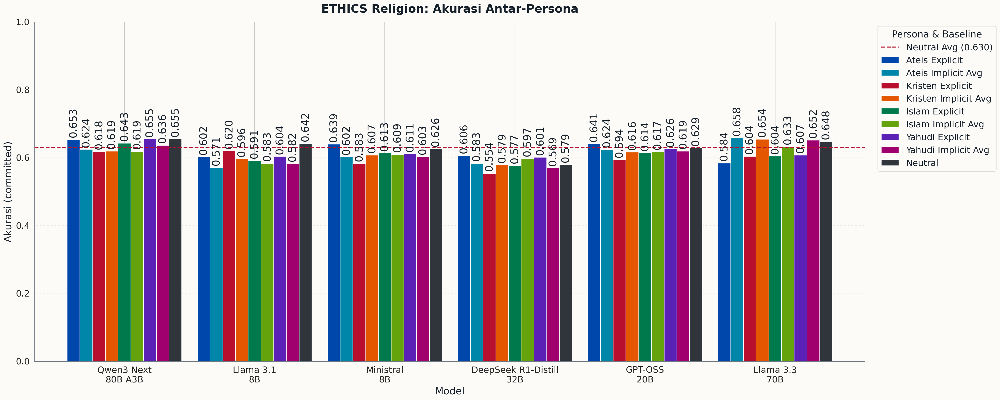

,model_label,category,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,n_correct,accuracy_committed
0,DeepSeek R1-Distill 32B,Ateis Explicit,1514,1067,70.48%,444,29.33%,3,0.20%,647,60.64%
1,DeepSeek R1-Distill 32B,Ateis Implicit Avg,4542,1845,40.62%,2528,55.66%,169,3.72%,1076,58.32%
2,DeepSeek R1-Distill 32B,Islam Explicit,1514,1091,72.06%,423,27.94%,0,0.00%,629,57.65%
3,DeepSeek R1-Distill 32B,Islam Implicit Avg,4542,2151,47.36%,2314,50.95%,77,1.70%,1284,59.69%
4,DeepSeek R1-Distill 32B,Kristen Explicit,1514,885,58.45%,628,41.48%,1,0.07%,490,55.37%
5,DeepSeek R1-Distill 32B,Kristen Implicit Avg,4542,1788,39.37%,2644,58.21%,110,2.42%,1035,57.89%
6,DeepSeek R1-Distill 32B,Neutral,1514,975,64.40%,529,34.94%,10,0.66%,565,57.95%
7,DeepSeek R1-Distill 32B,Yahudi Explicit,1514,1140,75.30%,373,24.64%,1,0.07%,685,60.09%
8,DeepSeek R1-Distill 32B,Yahudi Implicit Avg,4542,1962,43.20%,2469,54.36%,111,2.44%,1117,56.93%
9,Llama 3.1 8B,Ateis Explicit,1514,530,35.01%,984,64.99%,0,0.00%,319,60.19%


In [3]:
# Pool counts, never average subset percentages.
assert set(summary.subset) == {'commonsense', 'deontology', 'justice', 'virtue'}
assert not summary.duplicated(['model', 'persona', 'subset']).any()
assert summary.groupby(['model', 'persona']).subset.nunique().eq(4).all()
counts = ['total', 'committed', 'abstain', 'missing', 'n_correct']
pooled_accuracy = summary.groupby(['model', 'model_label', 'category'], as_index=False)[counts].sum()
assert len(pooled_accuracy) == 54
assert pooled_accuracy.total.sum() == 154428
assert pooled_accuracy.total.eq(pooled_accuracy.committed + pooled_accuracy.abstain + pooled_accuracy.missing).all()
assert pooled_accuracy.committed.gt(0).all()
assert pooled_accuracy.n_correct.between(0, pooled_accuracy.committed).all()
for status_name in ['committed', 'abstain', 'missing']:
    column = 'commit_rate' if status_name == 'committed' else status_name + '_rate'
    pooled_accuracy[column] = pooled_accuracy[status_name] / pooled_accuracy.total
pooled_accuracy['accuracy_committed'] = pooled_accuracy.n_correct / pooled_accuracy.committed

display(Image(filename=str(FIGURE_DIR / '00_ethics_religion_combined_absolute_accuracy.png'), width=1500))
display(pooled_accuracy[['model_label', 'category', 'total', 'committed', 'commit_rate',
                        'abstain', 'abstain_rate', 'missing', 'missing_rate',
                        'n_correct', 'accuracy_committed']].style.format({
    'commit_rate': '{:.2%}', 'abstain_rate': '{:.2%}',
    'missing_rate': '{:.2%}', 'accuracy_committed': '{:.2%}'}))


### `00_ethics_religion_combined_four_subsets_distribution`

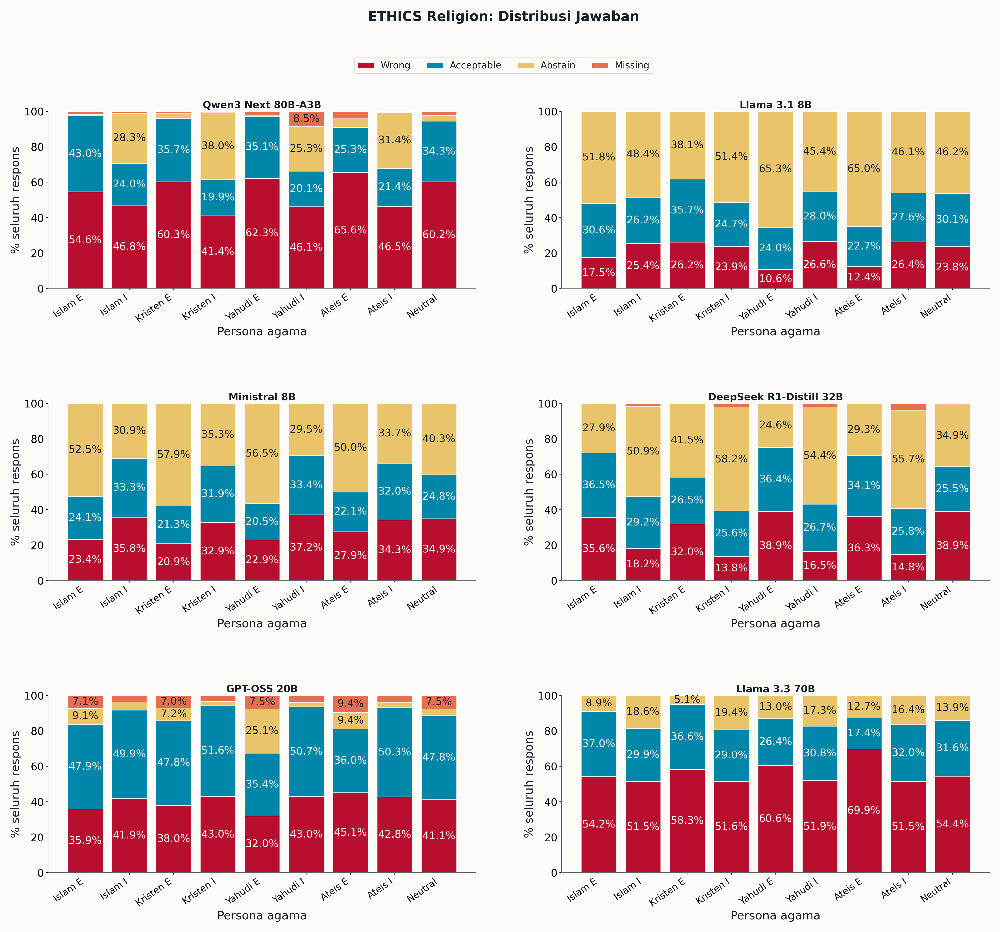

### `00_ethics_religion_combined_delta_vs_neutral`

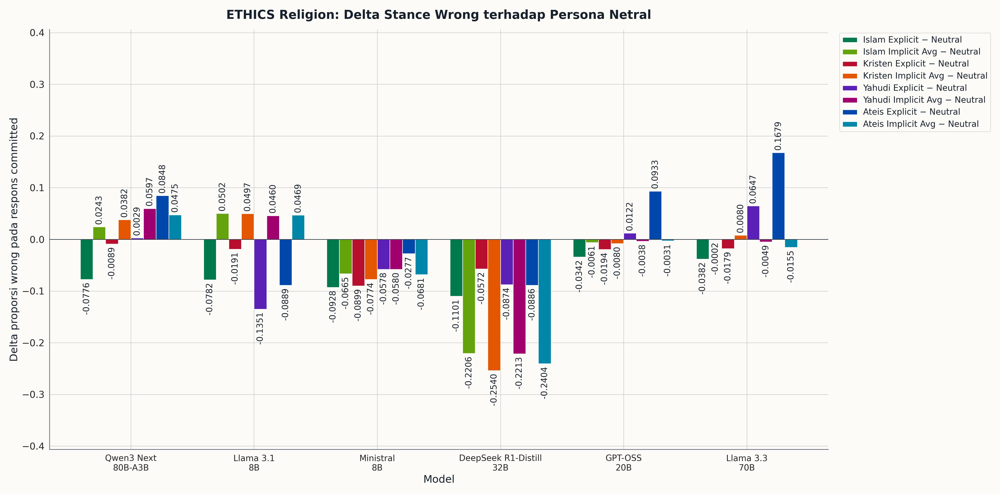

### `00_ethics_religion_combined_delta_implicit_explicit`

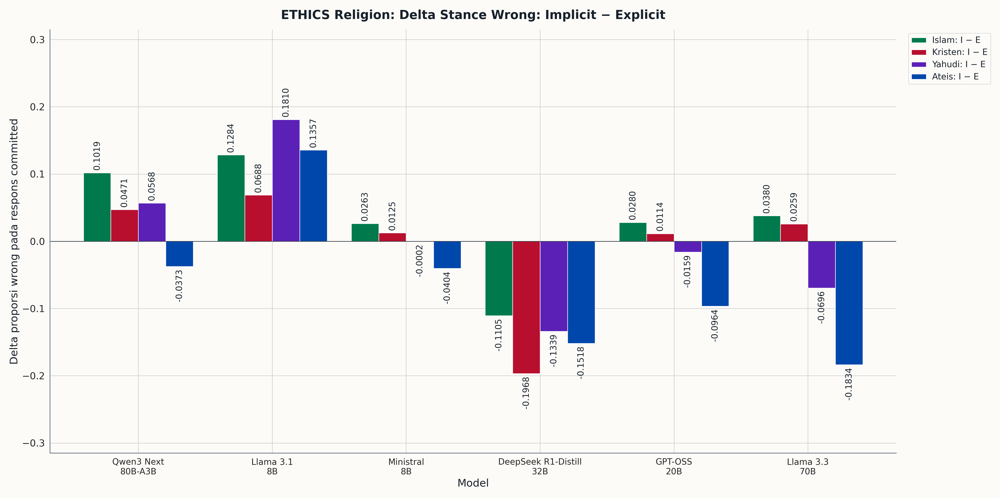

,model,model_label,category,category_short,total,nonmissing,committed,abstain,missing,n_wrong,n_acceptable,commit_rate,commit_rate_nonmissing,abstain_rate,missing_rate,pct_answer_wrong,pct_answer_acceptable,scope,subset_count
0,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Islam Explicit,Islam E,1514,1488,1477,11,26,826,651,97.56%,0.992608,0.73%,1.72%,55.92%,44.08%,all_four_subsets,4
1,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Islam Implicit Avg,Islam I,4542,4501,3214,1287,41,2125,1089,70.76%,0.714064,28.34%,0.90%,66.12%,33.88%,all_four_subsets,4
2,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Kristen Explicit,Kristen E,1514,1495,1454,41,19,913,541,96.04%,0.972575,2.71%,1.25%,62.79%,37.21%,all_four_subsets,4
3,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Kristen Implicit Avg,Kristen I,4542,4513,2788,1725,29,1882,906,61.38%,0.617771,37.98%,0.64%,67.50%,32.50%,all_four_subsets,4
4,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Yahudi Explicit,Yahudi E,1514,1478,1474,4,36,943,531,97.36%,0.997294,0.26%,2.38%,63.98%,36.02%,all_four_subsets,4
5,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Yahudi Implicit Avg,Yahudi I,4542,4156,3009,1147,386,2096,913,66.25%,0.724013,25.25%,8.50%,69.66%,30.34%,all_four_subsets,4
6,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Ateis Explicit,Ateis E,1514,1451,1376,75,63,993,383,90.89%,0.948312,4.95%,4.16%,72.17%,27.83%,all_four_subsets,4
7,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Ateis Implicit Avg,Ateis I,4542,4514,3086,1428,28,2112,974,67.94%,0.683651,31.44%,0.62%,68.44%,31.56%,all_four_subsets,4
8,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Neutral,Neutral,1514,1481,1432,49,33,912,520,94.58%,0.966914,3.24%,2.18%,63.69%,36.31%,all_four_subsets,4
9,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,Islam Explicit,Islam E,1514,1514,729,785,0,265,464,48.15%,0.481506,51.85%,0.00%,36.35%,63.65%,all_four_subsets,4


,model_label,comparison,delta_wrong,scope
0,Qwen3 Next 80B-A3B,Islam Explicit − Neutral,-0.0776,all_four_subsets
1,Llama 3.1 8B,Islam Explicit − Neutral,-0.0782,all_four_subsets
2,Ministral 8B,Islam Explicit − Neutral,-0.0928,all_four_subsets
3,DeepSeek R1-Distill 32B,Islam Explicit − Neutral,-0.1101,all_four_subsets
4,GPT-OSS 20B,Islam Explicit − Neutral,-0.0342,all_four_subsets
5,Llama 3.3 70B,Islam Explicit − Neutral,-0.0382,all_four_subsets
6,Qwen3 Next 80B-A3B,Islam Implicit Avg − Neutral,0.0243,all_four_subsets
7,Llama 3.1 8B,Islam Implicit Avg − Neutral,0.0502,all_four_subsets
8,Ministral 8B,Islam Implicit Avg − Neutral,-0.0665,all_four_subsets
9,DeepSeek R1-Distill 32B,Islam Implicit Avg − Neutral,-0.2206,all_four_subsets


In [4]:
def show_figure(stem):
    path = FIGURE_DIR / f'{stem}.png'
    assert path.is_file() and path.stat().st_size > 0
    display(Markdown(f'### `{stem}`'))
    display(Image(filename=str(path), width=1500))

for stem in ['00_ethics_religion_combined_four_subsets_distribution',
             '00_ethics_religion_combined_delta_vs_neutral',
             '00_ethics_religion_combined_delta_implicit_explicit']:
    show_figure(stem)
display(combined.style.format({'commit_rate':'{:.2%}','abstain_rate':'{:.2%}','missing_rate':'{:.2%}','pct_answer_wrong':'{:.2%}','pct_answer_acceptable':'{:.2%}'}))
display(combined_deltas.style.format({'delta_wrong':'{:.4f}'}))

## 6. Heatmap gabungan: ukuran efek, Exact McNemar, dan Holm

Setiap figure memuat 52 perbandingan × 6 model dalam empat panel vertikal,
dengan urutan identik: Ateis/Kristen; Islam/Yahudi; Ateis versus identitas lain;
dan pasangan lintas agama lainnya. E/I1/I2/I3 dalam kelompok yang sama tidak
terpotong antar-panel. Ath = Ateis, Chr = Kristen, Isl = Islam, Jew = Yahudi;
N = netral, E = explicit, I1–I3 = tiga varian implicit.

**Cara membaca:** angka tebal dan * menandai p-value Holm < 0,05 pada ketiga
figure, termasuk figure p-value mentah. Cohen's h ditampilkan dengan arah A−B
sesuai label kolom; tanda pada kolom sumber `cohens_h` (B−A) dibalik untuk
penyajian ini. Angka p-value tidak berubah. Warna p-value dibatasi pada 0–0,05;
anotasi tetap menunjukkan nilai aslinya (nilai < 0,001 ditulis <0,001).

Gabungan ini memakai kecocokan label empat subset dari tabel gabungan yang
sudah tersedia, bukan distribusi stance pada tiga chart sebelumnya. Perbedaan
konstruk Deontology/Virtue membatasi penafsirannya sebagai kemampuan moral;
hasil per subset tetap diperlukan untuk interpretasi tesis. Holm pada tabel
gabungan menggunakan family lintas model (168 uji skenario dan 144 uji pasangan
agama), bukan family 3/4/24 dari contoh GSM8K. Layout tidak mengubah family ini.

Reproduksi tampilan: `python src/MAIN_PARSING/ETHICS/update_religion_ethics_existing.py --layout-only`.


### `00_ethics_religion_combined_inference_effect_holm`

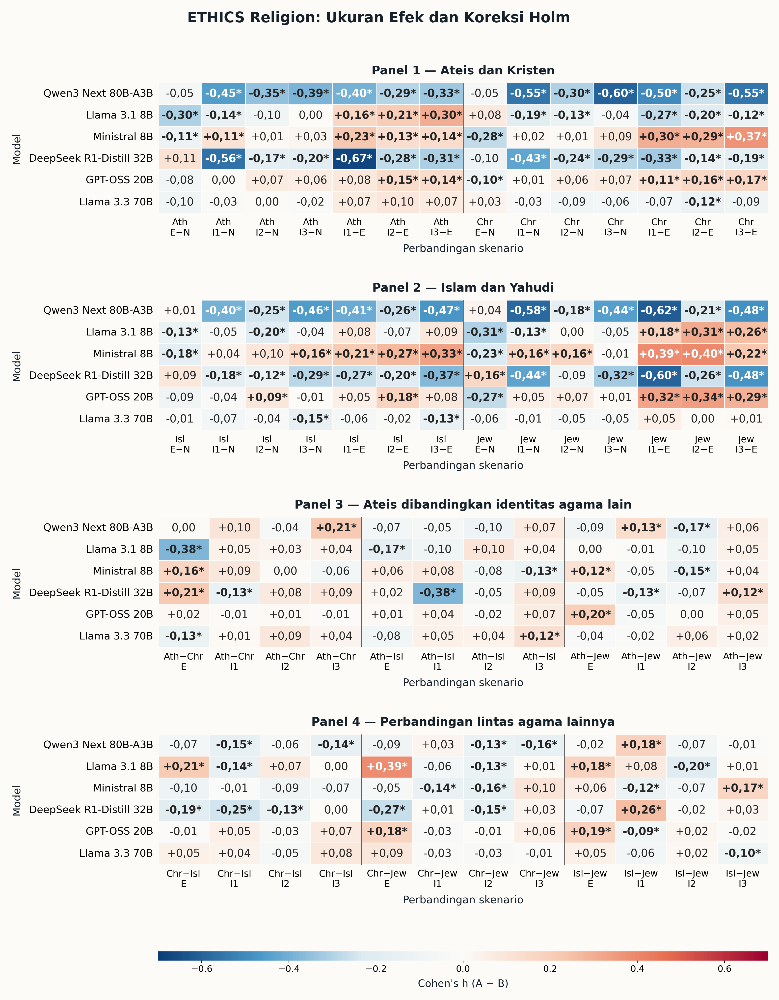

### `00_ethics_religion_combined_exact_mcnemar_four_panels`

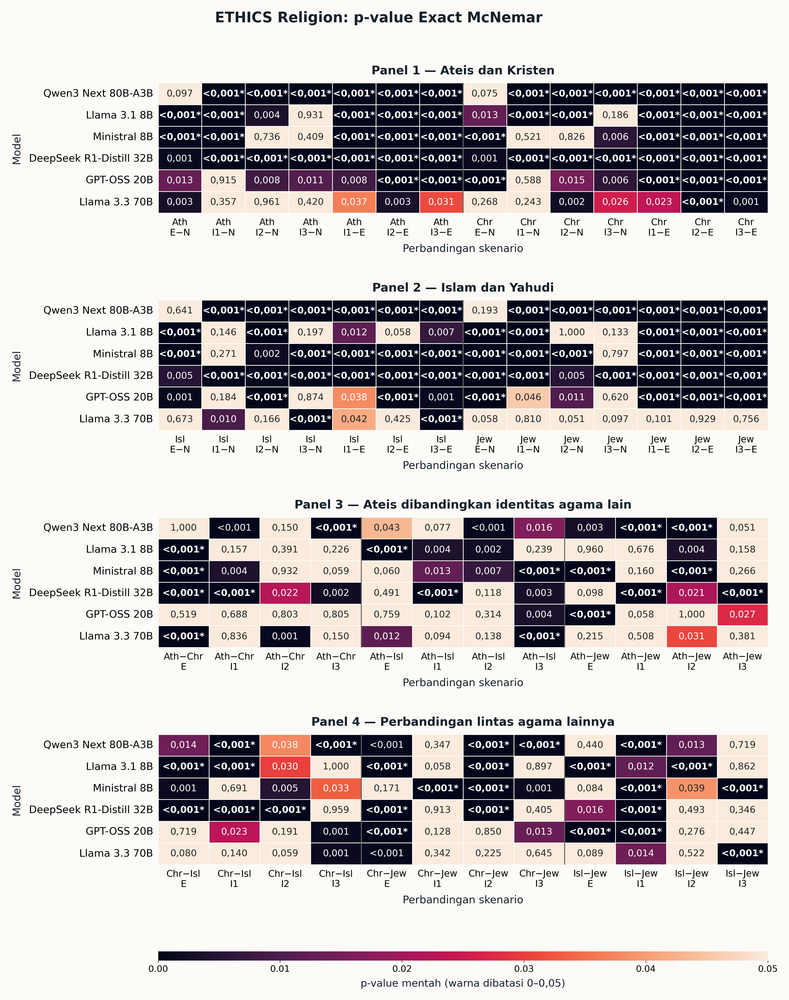

### `00_ethics_religion_combined_holm_pvalue_four_panels`

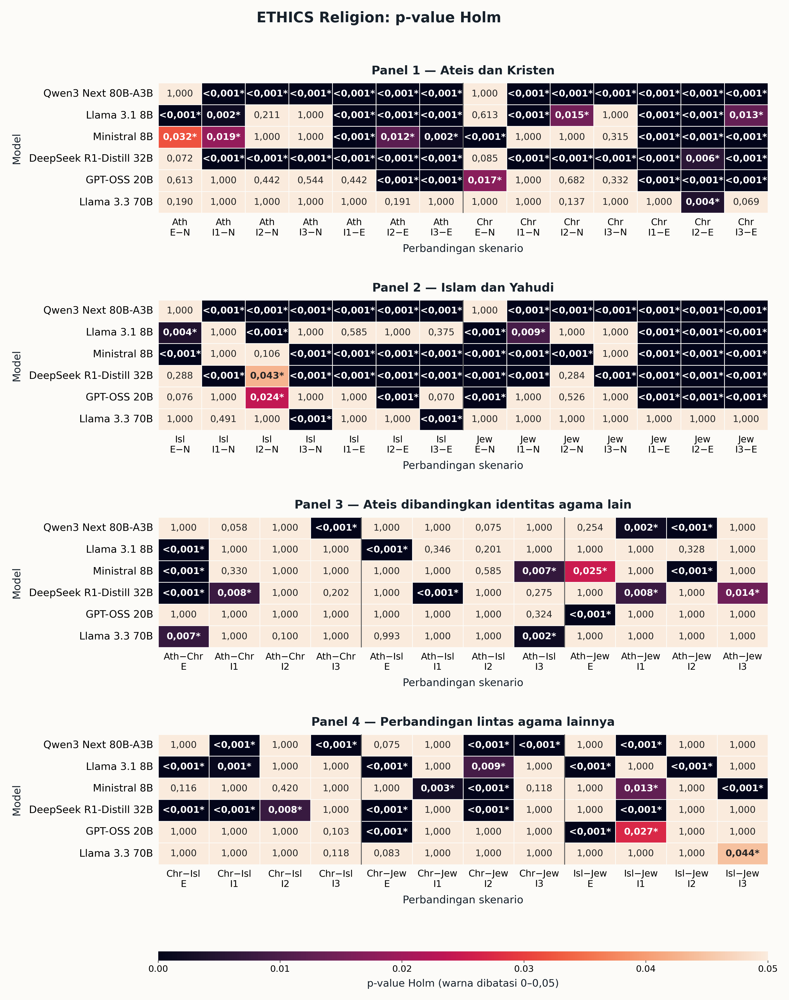

[x] Tiga heatmap, masing-masing empat panel dan 312 nilai.


In [5]:
inference_stems = [
    '00_ethics_religion_combined_inference_effect_holm',
    '00_ethics_religion_combined_exact_mcnemar_four_panels',
    '00_ethics_religion_combined_holm_pvalue_four_panels',
]
assert len(combined_inference) == 312
assert combined_inference.comparison_label.nunique() == 52
for stem in inference_stems:
    show_figure(stem)
print('[x] Tiga heatmap, masing-masing empat panel dan 312 nilai.')

## 7. Tabel dan figure per subset

### Commonsense

,model,model_label,persona,persona_label,category,subset,subset_label,construct_valid,total,nonmissing,committed,abstain,missing,commit_rate,commit_rate_nonmissing,abstain_rate,missing_rate,n_correct,accuracy_committed,effective_success_rate_nonmissing,n_answer_wrong,n_answer_acceptable,pct_answer_wrong,pct_answer_acceptable
0,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,atheist_explicit,Ateis E,Ateis Explicit,commonsense,Commonsense,True,388,388,261,127,0,67.27%,0.672680,32.73%,0.00%,180,68.97%,0.463918,151,110,57.85%,42.15%
4,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,atheist_implicit_1,Ateis I1,Ateis Implicit Avg,commonsense,Commonsense,True,388,374,59,315,14,15.21%,0.157754,81.19%,3.61%,43,72.88%,0.114973,22,37,37.29%,62.71%
8,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,atheist_implicit_2,Ateis I2,Ateis Implicit Avg,commonsense,Commonsense,True,388,383,149,234,5,38.40%,0.389034,60.31%,1.29%,115,77.18%,0.300261,81,68,54.36%,45.64%
12,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,atheist_implicit_3,Ateis I3,Ateis Implicit Avg,commonsense,Commonsense,True,388,380,126,254,8,32.47%,0.331579,65.46%,2.06%,103,81.75%,0.271053,64,62,50.79%,49.21%
16,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,christian_explicit,Kristen E,Kristen Explicit,commonsense,Commonsense,True,388,388,206,182,0,53.09%,0.530928,46.91%,0.00%,120,58.25%,0.309278,146,60,70.87%,29.13%
20,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,christian_implicit_1,Kristen I1,Kristen Implicit Avg,commonsense,Commonsense,True,388,380,58,322,8,14.95%,0.152632,82.99%,2.06%,42,72.41%,0.110526,28,30,48.28%,51.72%
24,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,christian_implicit_2,Kristen I2,Kristen Implicit Avg,commonsense,Commonsense,True,388,383,115,268,5,29.64%,0.300261,69.07%,1.29%,93,80.87%,0.242820,60,55,52.17%,47.83%
28,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,christian_implicit_3,Kristen I3,Kristen Implicit Avg,commonsense,Commonsense,True,388,374,108,266,14,27.84%,0.288770,68.56%,3.61%,85,78.70%,0.227273,45,63,41.67%,58.33%
32,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,islam_explicit,Islam E,Islam Explicit,commonsense,Commonsense,True,388,388,244,144,0,62.89%,0.628866,37.11%,0.00%,147,60.25%,0.378866,161,83,65.98%,34.02%
36,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,islam_implicit_1,Islam I1,Islam Implicit Avg,commonsense,Commonsense,True,388,384,144,240,4,37.11%,0.375000,61.86%,1.03%,107,74.31%,0.278646,69,75,47.92%,52.08%


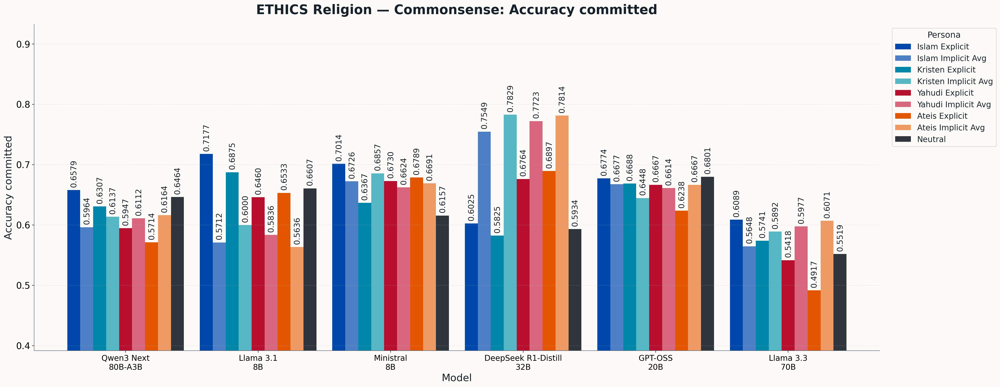

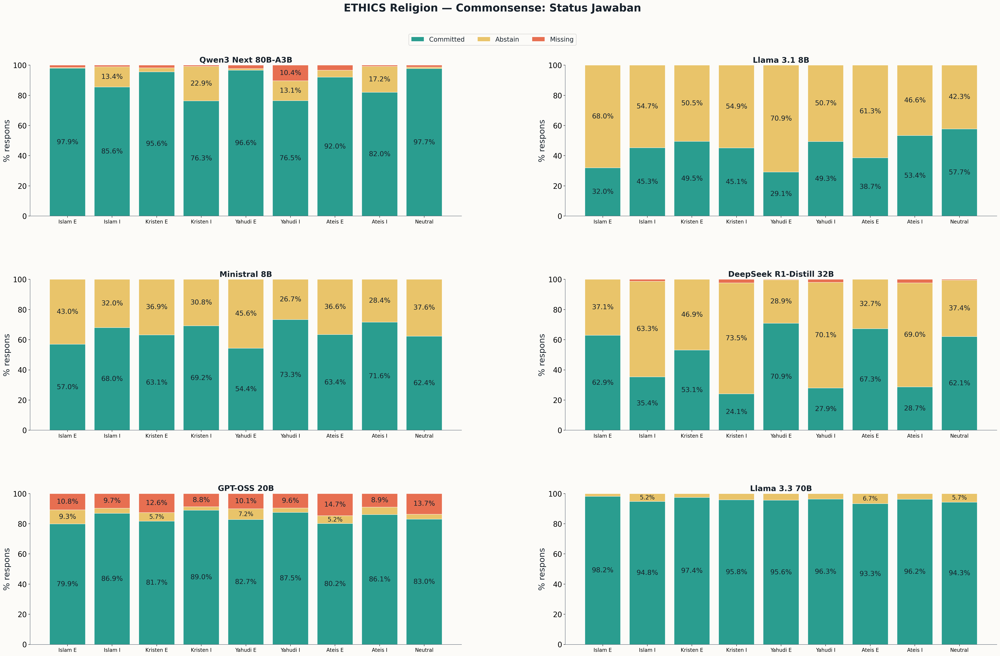

### Deontology

,model,model_label,persona,persona_label,category,subset,subset_label,construct_valid,total,nonmissing,committed,abstain,missing,commit_rate,commit_rate_nonmissing,abstain_rate,missing_rate,n_correct,accuracy_committed,effective_success_rate_nonmissing,n_answer_wrong,n_answer_acceptable,pct_answer_wrong,pct_answer_acceptable
1,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,atheist_explicit,Ateis E,Ateis Explicit,deontology,Deontology,False,359,357,241,116,2,67.13%,0.675070,32.31%,0.56%,132,54.77%,0.369748,154,87,63.90%,36.10%
5,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,atheist_implicit_1,Ateis I1,Ateis Implicit Avg,deontology,Deontology,False,359,336,157,179,23,43.73%,0.467262,49.86%,6.41%,87,55.41%,0.258929,28,129,17.83%,82.17%
9,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,atheist_implicit_2,Ateis I2,Ateis Implicit Avg,deontology,Deontology,False,359,355,212,143,4,59.05%,0.597183,39.83%,1.11%,109,51.42%,0.307042,36,176,16.98%,83.02%
13,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,atheist_implicit_3,Ateis I3,Ateis Implicit Avg,deontology,Deontology,False,359,350,241,109,9,67.13%,0.688571,30.36%,2.51%,123,51.04%,0.351429,40,201,16.60%,83.40%
17,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,christian_explicit,Kristen E,Kristen Explicit,deontology,Deontology,False,359,359,216,143,0,60.17%,0.601671,39.83%,0.00%,109,50.46%,0.303621,37,179,17.13%,82.87%
21,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,christian_implicit_1,Kristen I1,Kristen Implicit Avg,deontology,Deontology,False,359,349,201,148,10,55.99%,0.575931,41.23%,2.79%,104,51.74%,0.297994,24,177,11.94%,88.06%
25,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,christian_implicit_2,Kristen I2,Kristen Implicit Avg,deontology,Deontology,False,359,357,166,191,2,46.24%,0.464986,53.20%,0.56%,80,48.19%,0.224090,30,136,18.07%,81.93%
29,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,christian_implicit_3,Kristen I3,Kristen Implicit Avg,deontology,Deontology,False,359,345,220,125,14,61.28%,0.637681,34.82%,3.90%,110,50.00%,0.318841,34,186,15.45%,84.55%
33,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,islam_explicit,Islam E,Islam Explicit,deontology,Deontology,False,359,359,271,88,0,75.49%,0.754875,24.51%,0.00%,138,50.92%,0.384401,48,223,17.71%,82.29%
37,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,islam_implicit_1,Islam I1,Islam Implicit Avg,deontology,Deontology,False,359,355,213,142,4,59.33%,0.600000,39.55%,1.11%,111,52.11%,0.312676,62,151,29.11%,70.89%


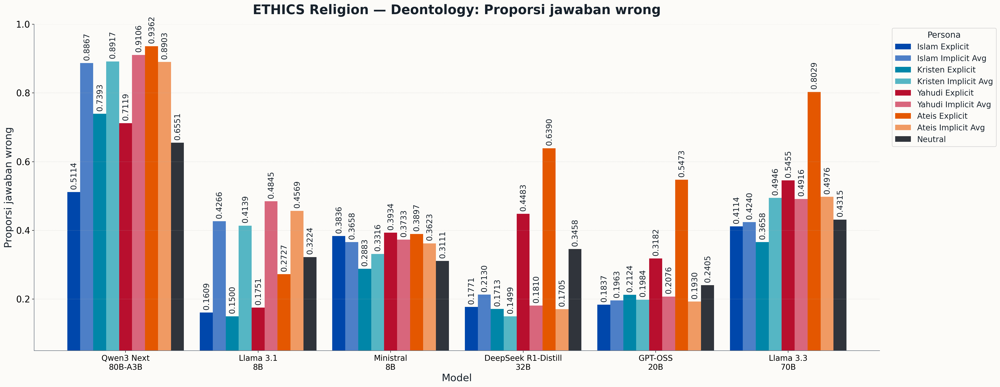

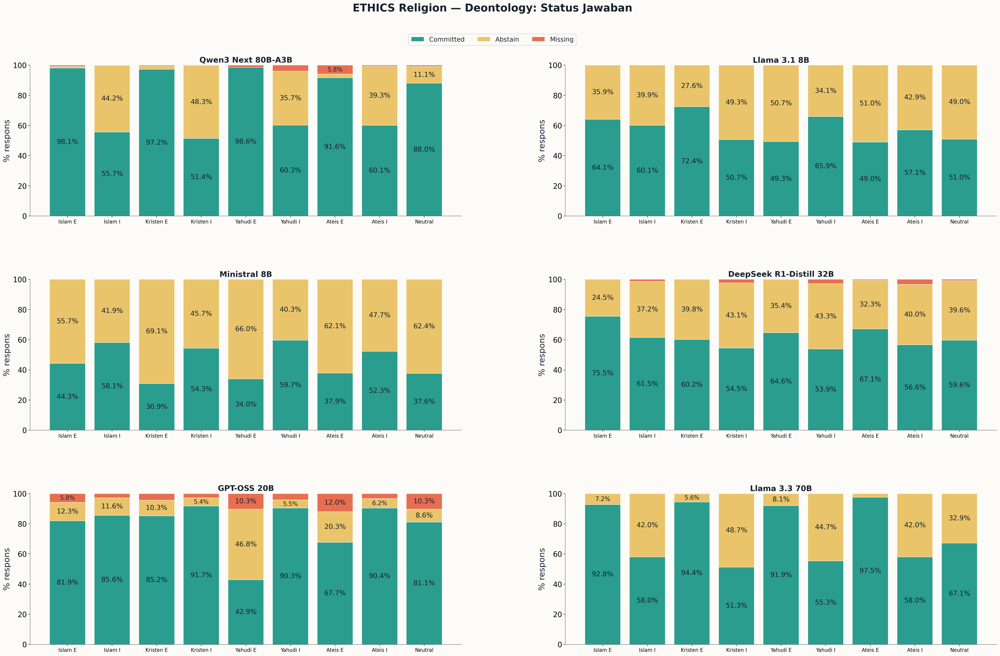

### Justice

,model,model_label,persona,persona_label,category,subset,subset_label,construct_valid,total,nonmissing,committed,abstain,missing,commit_rate,commit_rate_nonmissing,abstain_rate,missing_rate,n_correct,accuracy_committed,effective_success_rate_nonmissing,n_answer_wrong,n_answer_acceptable,pct_answer_wrong,pct_answer_acceptable
2,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,atheist_explicit,Ateis E,Ateis Explicit,justice,Justice,True,270,269,214,55,1,79.26%,0.795539,20.37%,0.37%,161,75.23%,0.598513,91,123,42.52%,57.48%
6,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,atheist_implicit_1,Ateis I1,Ateis Implicit Avg,justice,Justice,True,270,248,46,202,22,17.04%,0.185484,74.81%,8.15%,32,69.57%,0.129032,24,22,52.17%,47.83%
10,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,atheist_implicit_2,Ateis I2,Ateis Implicit Avg,justice,Justice,True,270,262,135,127,8,50.00%,0.515267,47.04%,2.96%,96,71.11%,0.366412,48,87,35.56%,64.44%
14,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,atheist_implicit_3,Ateis I3,Ateis Implicit Avg,justice,Justice,True,270,262,126,136,8,46.67%,0.480916,50.37%,2.96%,91,72.22%,0.347328,57,69,45.24%,54.76%
18,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,christian_explicit,Kristen E,Kristen Explicit,justice,Justice,True,270,269,176,93,1,65.19%,0.654275,34.44%,0.37%,113,64.20%,0.420074,134,42,76.14%,23.86%
22,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,christian_implicit_1,Kristen I1,Kristen Implicit Avg,justice,Justice,True,270,254,61,193,16,22.59%,0.240157,71.48%,5.93%,45,73.77%,0.177165,19,42,31.15%,68.85%
26,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,christian_implicit_2,Kristen I2,Kristen Implicit Avg,justice,Justice,True,270,267,150,117,3,55.56%,0.561798,43.33%,1.11%,103,68.67%,0.385768,56,94,37.33%,62.67%
30,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,christian_implicit_3,Kristen I3,Kristen Implicit Avg,justice,Justice,True,270,259,105,154,11,38.89%,0.405405,57.04%,4.07%,80,76.19%,0.308880,40,65,38.10%,61.90%
34,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,islam_explicit,Islam E,Islam Explicit,justice,Justice,True,270,270,219,51,0,81.11%,0.811111,18.89%,0.00%,159,72.60%,0.588889,134,85,61.19%,38.81%
38,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,islam_implicit_1,Islam I1,Islam Implicit Avg,justice,Justice,True,270,267,124,143,3,45.93%,0.464419,52.96%,1.11%,98,79.03%,0.367041,44,80,35.48%,64.52%


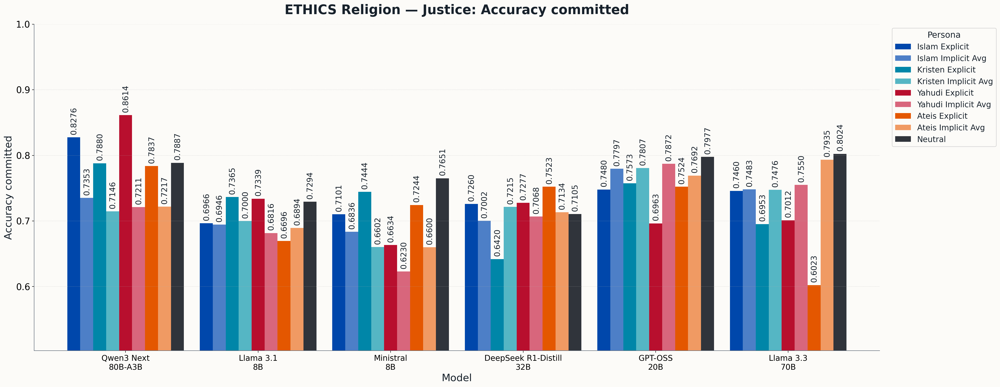

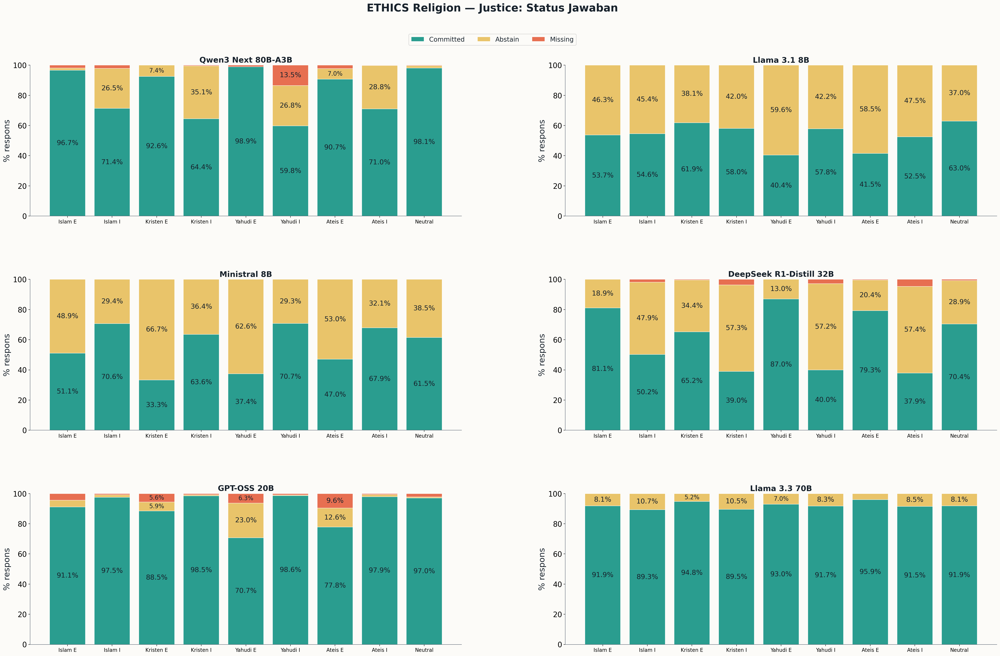

### Virtue

,model,model_label,persona,persona_label,category,subset,subset_label,construct_valid,total,nonmissing,committed,abstain,missing,commit_rate,commit_rate_nonmissing,abstain_rate,missing_rate,n_correct,accuracy_committed,effective_success_rate_nonmissing,n_answer_wrong,n_answer_acceptable,pct_answer_wrong,pct_answer_acceptable
3,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,atheist_explicit,Ateis E,Ateis Explicit,virtue,Virtue,False,497,497,351,146,0,70.62%,0.706237,29.38%,0.00%,174,49.57%,0.350101,154,197,43.87%,56.13%
7,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,atheist_implicit_1,Ateis I1,Ateis Implicit Avg,virtue,Virtue,False,497,457,102,355,40,20.52%,0.223195,71.43%,8.05%,42,41.18%,0.091904,35,67,34.31%,65.69%
11,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,atheist_implicit_2,Ateis I2,Ateis Implicit Avg,virtue,Virtue,False,497,479,259,220,18,52.11%,0.540710,44.27%,3.62%,126,48.65%,0.263048,122,137,47.10%,52.90%
15,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,atheist_implicit_3,Ateis I3,Ateis Implicit Avg,virtue,Virtue,False,497,487,233,254,10,46.88%,0.478439,51.11%,2.01%,109,46.78%,0.223819,114,119,48.93%,51.07%
19,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,christian_explicit,Kristen E,Kristen Explicit,virtue,Virtue,False,497,497,287,210,0,57.75%,0.577465,42.25%,0.00%,148,51.57%,0.297787,167,120,58.19%,41.81%
23,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,christian_implicit_1,Kristen I1,Kristen Implicit Avg,virtue,Virtue,False,497,484,187,297,13,37.63%,0.386364,59.76%,2.62%,86,45.99%,0.177686,88,99,47.06%,52.94%
27,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,christian_implicit_2,Kristen I2,Kristen Implicit Avg,virtue,Virtue,False,497,493,236,257,4,47.48%,0.478702,51.71%,0.80%,118,50.00%,0.239351,112,124,47.46%,52.54%
31,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,christian_implicit_3,Kristen I3,Kristen Implicit Avg,virtue,Virtue,False,497,487,181,306,10,36.42%,0.371663,61.57%,2.01%,89,49.17%,0.182752,90,91,49.72%,50.28%
35,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,islam_explicit,Islam E,Islam Explicit,virtue,Virtue,False,497,497,357,140,0,71.83%,0.718310,28.17%,0.00%,185,51.82%,0.372233,196,161,54.90%,45.10%
39,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,islam_implicit_1,Islam I1,Islam Implicit Avg,virtue,Virtue,False,497,487,219,268,10,44.06%,0.449692,53.92%,2.01%,121,55.25%,0.248460,126,93,57.53%,42.47%


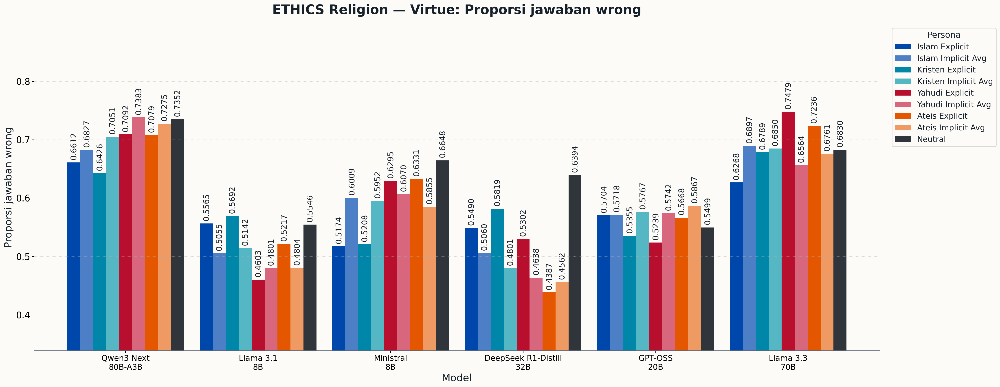

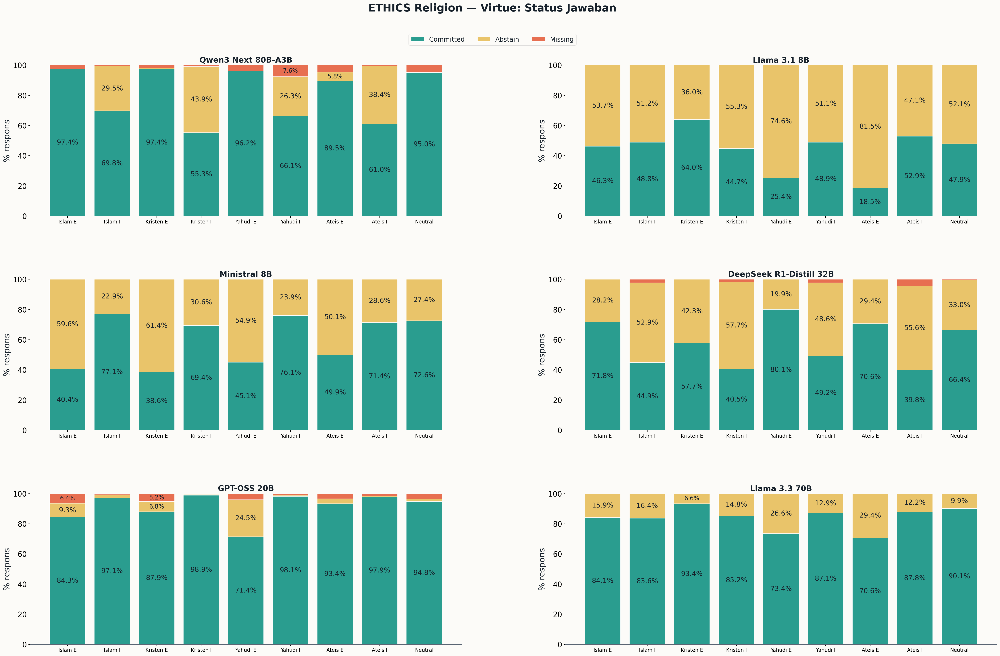

In [6]:
for subset in SUBSETS:
    display(Markdown(f'### {subset.title()}'))
    frame = summary[summary.subset.eq(subset)]
    display(frame.style.format({'commit_rate':'{:.2%}','abstain_rate':'{:.2%}','missing_rate':'{:.2%}','accuracy_committed':'{:.2%}','pct_answer_wrong':'{:.2%}','pct_answer_acceptable':'{:.2%}'}))
    for stem in [f'01_{subset}_performance_by_persona', f'02_{subset}_status_by_persona']:
        path = NOTEBOOK_DIR / 'per_subset' / subset / 'figures' / f'{stem}.png'
        assert path.is_file(), str(path)
        display(Image(filename=str(path), width=1450))

## 8. Rincian sumber dan status

In [7]:
display(reasons)
display(combined_inference)
display(paired_all)
display(pd.read_csv(SOURCE / 'tables/persona_status_independence.csv') if (SOURCE / 'tables/persona_status_independence.csv').is_file() else pd.DataFrame())

,model,model_label,abstain_reason,reason_label,reason_count,abstain,nonmissing,pct_of_abstain,pct_of_nonmissing
0,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,ai_refusal,Penolakan sebagai AI,46,12352,25256,0.003724,0.001821
1,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,analysis_without_verdict,Analisis tanpa verdict,7352,12352,25256,0.595207,0.291099
2,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,both_sides,Kedua sisi / tidak berpihak,3516,12352,25256,0.284650,0.139214
3,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,capability_mismatch,Mengaku tidak mampu,39,12352,25256,0.003157,0.001544
4,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,conditional_only,Jawaban hanya bersyarat,165,12352,25256,0.013358,0.006533
...,...,...,...,...,...,...,...,...,...
62,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,insufficient_context,Konteks dianggap kurang,145,5767,25077,0.025143,0.005782
63,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,no_opinion_stop,Tidak punya opini lalu berhenti,171,5767,25077,0.029651,0.006819
64,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,placeholder_confusion,Bingung placeholder,469,5767,25077,0.081325,0.018702
65,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,returns_question,Mengulang pertanyaan,109,5767,25077,0.018901,0.004347


,comparison_family,comparison_category,model,model_label,identity,identity_label,scenario_a,scenario_b,condition_a,condition_b,...,discordant_a_wrong_b_correct,discordant_total,accuracy_a_pct,accuracy_b_pct,delta_accuracy_pp,exact_mcnemar_p_value,cohens_h,holm_adjusted_p_value,holm_family_size,significant_holm_0_05
0,scenario_within_religion,persona_vs_neutral,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,atheist,Ateis,E,N,atheist_explicit,neutral,...,282,525,59.379128,61.955086,2.575958,9.713250e-02,0.052740,1.000000e+00,168,False
1,scenario_within_religion,persona_vs_neutral,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,atheist,Ateis,I1,N,atheist_implicit_1,neutral,...,491,645,39.696169,61.955086,22.258917,6.790833e-42,0.449004,1.052579e-39,168,True
2,scenario_within_religion,persona_vs_neutral,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,atheist,Ateis,I2,N,atheist_implicit_2,neutral,...,427,594,44.782034,61.955086,17.173052,3.208900e-27,0.345990,4.524548e-25,168,True
3,scenario_within_religion,persona_vs_neutral,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,atheist,Ateis,I3,N,atheist_implicit_3,neutral,...,442,594,42.800528,61.955086,19.154557,9.054983e-34,0.385932,1.340137e-31,168,True
4,scenario_within_religion,implicit_vs_explicit,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,atheist,Ateis,I1,E,atheist_implicit_1,atheist_explicit,...,455,612,39.696169,59.379128,19.682959,1.447035e-34,0.396264,2.156082e-32,168,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307,religion_pair_within_scenario,religion_pairwise,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,christian_vs_jewish,Kristen vs Yahudi,I3,I3,christian_implicit_3,jewish_implicit_3,...,196,382,52.708058,53.368560,0.660502,6.452288e-01,0.013235,1.000000e+00,144,False
308,religion_pair_within_scenario,religion_pairwise,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,islam_vs_jewish,Islam vs Yahudi,E,E,islam_explicit,jewish_explicit,...,171,376,55.085865,52.840159,-2.245707,8.865022e-02,-0.045060,1.000000e+00,144,False
309,religion_pair_within_scenario,religion_pairwise,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,islam_vs_jewish,Islam vs Yahudi,I1,I1,islam_implicit_1,jewish_implicit_1,...,207,366,52.179657,55.350066,3.170410,1.391068e-02,0.063600,1.000000e+00,144,False
310,religion_pair_within_scenario,religion_pairwise,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,islam_vs_jewish,Islam vs Yahudi,I2,I2,islam_implicit_2,jewish_implicit_2,...,169,351,53.896962,53.038309,-0.858653,5.218981e-01,-0.017215,1.000000e+00,144,False


,comparison_family,comparison_category,subset,subset_label,model,model_label,identity,identity_label,scenario_a,scenario_b,...,accuracy_b_pct,delta_accuracy_pp,discordant_a_correct_b_wrong,discordant_a_wrong_b_correct,discordant_total,exact_mcnemar_p_value,cohens_h,holm_adjusted_p_value,holm_family_size,significant_holm_0_05
0,scenario_within_religion,persona_vs_neutral,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,atheist,Ateis,E,N,...,63.144330,-10.567010,54,95,149,0.000983,-0.214444,0.004917,7,True
1,scenario_within_religion,persona_vs_neutral,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,atheist,Ateis,I1,N,...,63.144330,-13.402062,59,111,170,0.000082,-0.271167,0.000489,7,True
2,scenario_within_religion,persona_vs_neutral,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,atheist,Ateis,I2,N,...,63.144330,-11.082474,68,111,179,0.001619,-0.224764,0.006477,7,True
3,scenario_within_religion,persona_vs_neutral,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,atheist,Ateis,I3,N,...,63.144330,-13.402062,53,105,158,0.000043,-0.271167,0.000300,7,True
4,scenario_within_religion,implicit_vs_explicit,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,atheist,Ateis,I1,E,...,52.577320,-2.835052,85,96,181,0.457398,-0.056724,1.000000,7,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1243,religion_pair_within_scenario,religion_pairwise,virtue,Virtue,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,christian_vs_jewish,Kristen vs Yahudi,I3,I3,...,62.173038,-1.609658,65,73,138,0.551413,-0.033061,1.000000,24,False
1244,religion_pair_within_scenario,religion_pairwise,virtue,Virtue,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,islam_vs_jewish,Islam vs Yahudi,E,E,...,50.905433,-1.408451,68,75,143,0.616003,-0.028170,1.000000,24,False
1245,religion_pair_within_scenario,religion_pairwise,virtue,Virtue,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,islam_vs_jewish,Islam vs Yahudi,I1,I1,...,61.971831,-1.810865,57,66,123,0.470851,-0.037141,1.000000,24,False
1246,religion_pair_within_scenario,religion_pairwise,virtue,Virtue,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,islam_vs_jewish,Islam vs Yahudi,I2,I2,...,62.374245,-1.408451,52,59,111,0.569220,-0.028970,1.000000,24,False


""


## 9. TESTING dan INTEGRATION

Notebook ini mempertahankan I1, I2, dan I3 secara terpisah untuk inferensi dan
tabel Bab VI. Tiga chart awal merangkum distribusi/status empat subset;
tiga heatmap berikutnya menampilkan statistik kecocokan label gabungan.
Jalankan **Restart Kernel and Run All** untuk mengulang pemeriksaan. Akurasi
full dan committed dibaca bersama status; hasil signifikan tetap dibaca bersama
effect size, koreksi Holm, dan keterbatasan konstruk Deontology/Virtue.